<a href="https://colab.research.google.com/github/Nithyashree2731/DAV/blob/main/Breastcancer1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 31)

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst

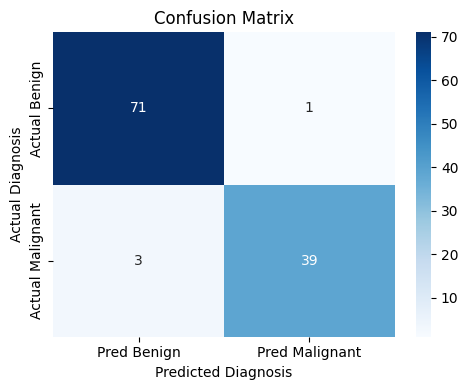


Top 5 Features Pushing Towards MALIGNANT:
                feature  coefficient
21        worst texture     1.434093
10         radius error     1.233325
28       worst symmetry     1.061264
7   mean concave points     0.952813
26      worst concavity     0.911406

Top 5 Features Pushing Towards BENIGN:
                    feature  coefficient
18           symmetry error    -0.330658
11            texture error    -0.407611
5          mean compactness    -0.439546
19  fractal dimension error    -0.593876
15        compactness error    -0.906925

Threshold  Precision  Recall  F1
0.1        0.891      0.976   0.932
0.3        0.976      0.976   0.976
0.5        0.975      0.929   0.951
0.7        1.000      0.905   0.950
0.9        1.000      0.786   0.880


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Load Dataset using sklearn's built-in Breast Cancer dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
# We'll map malignant to 1 and benign to 0 (sklearn uses 0 for malignant, 1 for benign, so we invert it to match your logic)
df["diagnosis"] = 1 - data.target

# 2. Data Preprocessing
# These columns are dropped for safety if using external datasets, but sklearn's version doesn't have them
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nClass Balance (1 = Malignant, 0 = Benign):")
print(df["diagnosis"].value_counts())

print("\nTotal Missing Values:", df.isnull().sum().sum())


# 3. Separate Features and Target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]


# 4. Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 5. Create Logistic Regression Pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])


# 6. Train the Model
model.fit(X_train, y_train)


# 7. Make Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


# 8. Calculate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:\n", cm)

print(f"\nTrue Negative (TN): {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")
print(f"True Positive (TP): {tp}")


# 9. Model Evaluation Metrics
print("\nMODEL PERFORMANCE")

print("Accuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC   :", round(roc_auc_score(y_test, y_prob), 4))


# 10. Classification Report
print("\nFull Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"]
    )
)


# 11. Visualize Confusion Matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")

plt.tight_layout()

plt.savefig("confusion_matrix.png")

plt.show()


# 12. Feature Importance Using Logistic Regression Coefficients
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
})

coef_df = coef_df.sort_values(
    by="coefficient",
    ascending=False
)

print("\nTop 5 Features Pushing Towards MALIGNANT:")
print(coef_df.head(5))

print("\nTop 5 Features Pushing Towards BENIGN:")
print(coef_df.tail(5))

# Print metrics at different classification thresholds
print("\nThreshold  Precision  Recall  F1")
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, pred_t, zero_division=0)
    r = recall_score(y_test, pred_t)
    f1 = f1_score(y_test, pred_t)
    print(f"{t:.1f}        {p:.3f}      {r:.3f}   {f1:.3f}")